In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 11장 심층 신경망 훈련

## 11.1 그레이디언트 소실과 폭주 문제

### 11.1.1 글로럿과 He 초기화

In [2]:
dense = tf.keras.layers.Dense(50, activation='relu', kernel_initializer='he_normal')

In [3]:
he_avg_init = tf.keras.initializers.VarianceScaling(scale=2., mode='fan_avg',
                                                    distribution='uniform')
dense = tf.keras.layers.Dense(50, activation='sigmoid', kernel_initializer=he_avg_init)

### 11.1.2 고급 활성화 함수

In [4]:
def plot_activ_func(funcs, axis):
    plt.hlines(0, axis[0], axis[1], color='black')
    plt.vlines(0, axis[2], axis[3], color='black')
    
    X = np.linspace(axis[0], axis[1], 500)
    linestyles = ['solid', 'dashed', 'dotted']
    for name, func, linestyle in funcs:
        plt.plot(X, func(X), alpha=0.8, label=name, linestyle=linestyles[linestyle])

    plt.axis(axis)
    plt.grid()
    plt.legend()

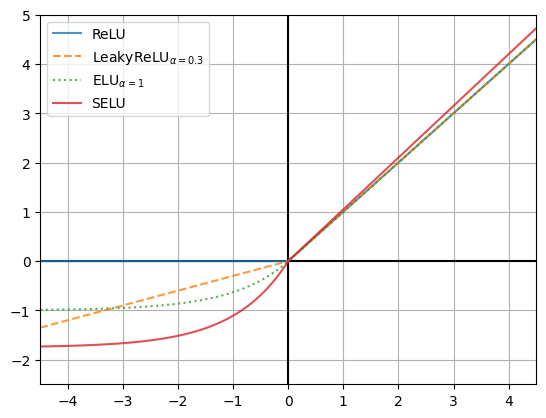

In [5]:
def approx_selu(z):
    return 1.05 * tf.keras.layers.ELU(alpha=1.67)(z)

plot_activ_func([('ReLU', tf.keras.layers.ReLU(), 0),
                 ('LeakyReLU$_{α=0.3}$', tf.keras.layers.LeakyReLU(negative_slope=0.3), 1),
                 ('ELU$_{α=1}$', tf.keras.layers.ELU(alpha=1.0), 2),
                 ('SELU', approx_selu, 0)
                ], axis=[-4.5, 4.5, -2.5, 5])
plt.show()

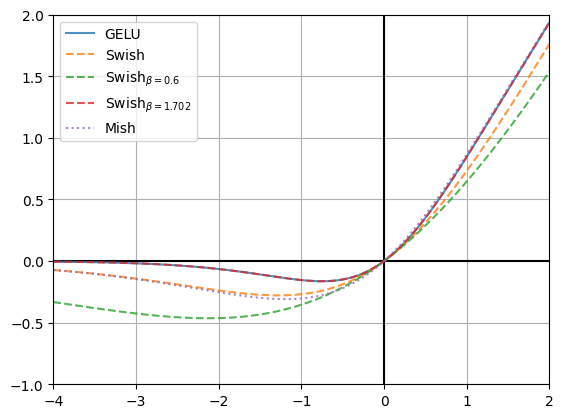

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class Swish:
    def __init__(self, beta=1):
        self.beta = beta
    def __call__(self, z):
        return z * sigmoid(self.beta * z)

def approx_gelu(z):
    return z * sigmoid(1.702 * z)

def mish(z):
    return z * np.tanh(np.log(1 + np.exp(z)))

plot_activ_func([('GELU', approx_gelu, 0),
                 ('Swish', Swish(), 1),
                 ('Swish$_{β=0.6}$', Swish(beta=0.6), 1),
                 ('Swish$_{β=1.702}$', Swish(beta=1.702), 1),
                 ('Mish', mish, 2)
                ], axis=[-4, 2, -1, 2])
plt.show()

$\text{ReLU} = \max(0, z)$

$\text{LeakyReLU}(z) = \max(\alpha z, z)$

$\text{ELU}_\alpha (z) = \begin{cases}
\alpha(e^z - 1) & \text{if }z<0 \\
z & \text{if }z\geq0
\end{cases}$

$\text{SELU}(z) = 1.05 \times \text{ELU}_{\alpha=1.67}(z)$

$\text{GELU}(z) = z\Phi(z)$

$\text{Swish}(z) = z\sigma(z) = \frac{z}{1 + e^{-z}}$

$\text{Mish}(z) = z\tanh(\text{softplus}(z)) = z\tanh(\log(1 + e^z))$

In [7]:
leaky_relu = tf.keras.layers.LeakyReLU(negative_slope=0.2)
dense = tf.keras.layers.Dense(50, activation=leaky_relu, kernel_initializer='he_normal')

In [8]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(50, kernel_initializer='he_normal'),
    tf.keras.layers.LeakyReLU(negative_slope=0.2)
])

### 11.1.3 배치 정규화

In [9]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(300, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [10]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 784)            │         3,136 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 300)            │         1,200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,346 (1.04 MB)

 Trainable params: 268,978 (1.03 MB)

 Non-trainable params: 2,368 (9.25 KB)

In [11]:
[(var.name, var.trainable) for var in model.layers[1].variables]

[('gamma', True),
 ('beta', True),
 ('moving_mean', False),
 ('moving_variance', False)]

In [12]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(300, kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.Dense(100, kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.Dense(10, activation='softmax')
])

### 11.1.4 그레이디언트 클리핑

In [13]:
optimizer = tf.keras.optimizers.SGD(clipvalue=1.0)

In [14]:
optimizer = tf.keras.optimizers.SGD(clipnorm=1.0)

## 11.2 사전 훈련된 층 재사용하기

### 11.2.1 케라스를 사용한 전이 학습

In [15]:
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]
X_train, X_valid, X_test = X_train / 255, X_valid / 255, X_test / 255

In [16]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [17]:
list(set(range(10)) - set([2, 3]))

[0, 1, 4, 5, 6, 7, 8, 9]

In [18]:
def split_data(X, y):
    pos_class_id = class_names.index('Sandal')
    neg_class_id = class_names.index('Shirt')
    
    idx_for_B = (y == pos_class_id) | (y == neg_class_id)
    X_A, y_A = X[~idx_for_B], y[~idx_for_B]
    X_B, y_B = X[idx_for_B], (y[idx_for_B] == pos_class_id).astype('float32')

    old_class_ids = list(set(range(10)) - set([pos_class_id, neg_class_id]))
    for old_class_id, new_class_id in zip(old_class_ids, range(8)):
        y_A[y_A == old_class_id] = new_class_id
    
    return (X_A, y_A), (X_B, y_B)

(X_train_A, y_train_A), (X_train_B, y_train_B) = split_data(X_train, y_train)
(X_valid_A, y_valid_A), (X_valid_B, y_valid_B) = split_data(X_valid, y_valid)
(X_test_A, y_test_A), (X_test_B, y_test_B) = split_data(X_test, y_test)

X_train_B = X_train_B[:200]
y_train_B = y_train_B[:200]

In [19]:
tf.random.set_seed(42)

model_A = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(8, activation='softmax')
])

model_A.compile(loss='sparse_categorical_crossentropy',
                optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
                metrics=['accuracy'])

history = model_A.fit(X_train_A, y_train_A, epochs=20, validation_data=(X_valid_A, y_valid_A))

Epoch 1/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 648us/step - accuracy: 0.6882 - loss: 1.1589 - val_accuracy: 0.8365 - val_loss: 0.6359
Epoch 2/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 596us/step - accuracy: 0.8422 - loss: 0.5358 - val_accuracy: 0.8610 - val_loss: 0.4532
Epoch 3/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 596us/step - accuracy: 0.8610 - loss: 0.4335 - val_accuracy: 0.8697 - val_loss: 0.3961
Epoch 4/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 594us/step - accuracy: 0.8710 - loss: 0.3899 - val_accuracy: 0.8762 - val_loss: 0.3662
Epoch 5/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 596us/step - accuracy: 0.8779 - loss: 0.3647 - val_accuracy: 0.8821 - val_loss: 0.3468
Epoch 6/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 593us/step - accuracy: 0.8828 - loss: 0.3479 - val_accuracy: 0.8849 - val_loss: 0.3327
Epoch 7/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 594us/step - accuracy: 0.8870 - loss: 0.3353 - val_accuracy: 0.8873 - val_loss: 0.3220
Epoch 8/20
1375/1375 ━━━━━━━━━━━━━━━━━━━━ 1s 595us/step - accuracy: 0.8907 -

In [20]:
tf.random.set_seed(42)

model_B = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_B.compile(loss='binary_crossentropy',
                optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
                metrics=['accuracy'])

history = model_B.fit(X_train_B, y_train_B, epochs=20, validation_data=(X_valid_B, y_valid_B))

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4900 - loss: 0.7439 - val_accuracy: 0.5196 - val_loss: 0.7199
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4950 - loss: 0.7018 - val_accuracy: 0.5299 - val_loss: 0.6851
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5150 - loss: 0.6694 - val_accuracy: 0.5557 - val_loss: 0.6571
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6100 - loss: 0.6432 - val_accuracy: 0.6381 - val_loss: 0.6342
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7150 - loss: 0.6216 - val_accuracy: 0.7526 - val_loss: 0.6151
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8300 - loss: 0.6034 - val_accuracy: 0.8330 - val_loss: 0.5986
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8750 - loss: 0.5874 - val_accuracy: 0.8814 - val_loss: 0.5840
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9000 - loss: 0.5732 - val_accuracy: 0.9062 - val_loss: 0.5710
Epoch 9

In [21]:
# model_A와 model_B_on_A는 일부 층 공유(상호 영향)
model_B_on_A = tf.keras.models.Sequential(model_A.layers[:-1])
model_B_on_A.add(tf.keras.layers.Dense(1, activation='sigmoid'))

In [22]:
model_A_clone = tf.keras.models.clone_model(model_A)
model_A_clone.set_weights(model_A.get_weights())

model_B_on_A = tf.keras.models.Sequential(model_A_clone.layers[:-1])
model_B_on_A.add(tf.keras.layers.Dense(1, activation='sigmoid'))

In [23]:
for layer in model_B_on_A.layers[:-1]:
    layer.trainable = False

optimizer = tf.keras.optimizers.SGD(learning_rate=0.001)
model_B_on_A.compile(loss='binary_crossentropy', optimizer=optimizer,
                     metrics=['accuracy'])

history = model_B_on_A.fit(X_train_B, y_train_B, epochs=4, validation_data=(X_valid_B, y_valid_B))

Epoch 1/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4050 - loss: 1.2123 - val_accuracy: 0.4113 - val_loss: 1.0408
Epoch 2/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3700 - loss: 0.9530 - val_accuracy: 0.4155 - val_loss: 0.8411
Epoch 3/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4500 - loss: 0.7832 - val_accuracy: 0.5381 - val_loss: 0.7157
Epoch 4/4
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6000 - loss: 0.6762 - val_accuracy: 0.6577 - val_loss: 0.6345


In [24]:
for layer in model_B_on_A.layers[:-1]:
    layer.trainable = True

optimizer = tf.keras.optimizers.SGD(learning_rate=0.001)
model_B_on_A.compile(loss='binary_crossentropy', optimizer=optimizer,
                     metrics=['accuracy'])

history = model_B_on_A.fit(X_train_B, y_train_B, epochs=16, validation_data=(X_valid_B, y_valid_B))

Epoch 1/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7500 - loss: 0.5802 - val_accuracy: 0.8412 - val_loss: 0.5249
Epoch 2/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8450 - loss: 0.4888 - val_accuracy: 0.9041 - val_loss: 0.4564
Epoch 3/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9450 - loss: 0.4274 - val_accuracy: 0.9505 - val_loss: 0.4058
Epoch 4/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9750 - loss: 0.3810 - val_accuracy: 0.9701 - val_loss: 0.3662
Epoch 5/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9800 - loss: 0.3444 - val_accuracy: 0.9794 - val_loss: 0.3342
Epoch 6/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9800 - loss: 0.3146 - val_accuracy: 0.9825 - val_loss: 0.3078
Epoch 7/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9800 - loss: 0.2900 - val_accuracy: 0.9835 - val_loss: 0.2857
Epoch 8/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9850 - loss: 0.2692 - val_accuracy: 0.9876 - val_loss: 0.2669
Epoch 9

In [25]:
model_B_on_A.evaluate(X_test_B, y_test_B)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 498us/step - accuracy: 0.9945 - loss: 0.1720


[0.17198428511619568, 0.9944999814033508]

## 11.3 고속 옵티마이저

### 11.3.1 모멘텀 최적화

In [26]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9)

### 11.3.2 네스테로프 가속 경사

In [27]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.001, momentum=0.9, nesterov=True)

### 11.3.4 RMSProp

In [28]:
optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.001, rho=0.9)

### 11.3.5 Adam

In [29]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)

### 11.3.9 학습률 스케줄링

In [30]:
def build_model(seed=42):
    tf.random.set_seed(seed)
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Dense(100, activation='relu', kernel_initializer="he_normal"),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

def build_and_train_model(optimizer):
    model = build_model()
    model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
                  metrics=['accuracy'])
    return model.fit(X_train, y_train, epochs=10, validation_data=(X_valid, y_valid))

#### 거듭제곱 기반 스케줄링

$\eta(t)=\frac{\eta_0}{(1+t/s)^c}$

In [31]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, weight_decay=1e-4)

In [32]:
lr_schedule = tf.keras.optimizers.schedules.InverseTimeDecay(
    initial_learning_rate=0.01,
    decay_steps=10_000,
    decay_rate=1.0,
    staircase=False
)
optimizer = tf.keras.optimizers.SGD(learning_rate=lr_schedule)

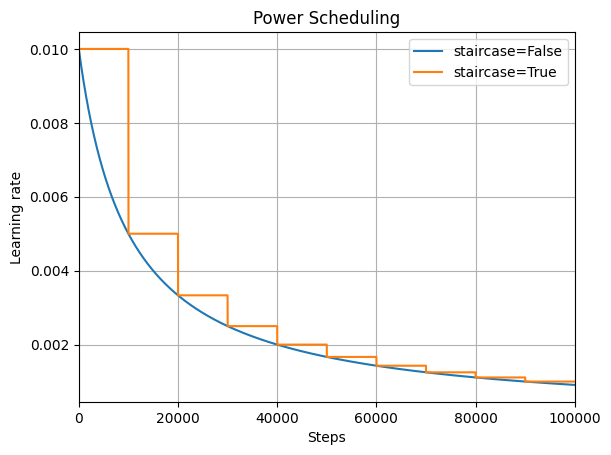

In [33]:
initial_learning_rate = 0.01
decay_rate = 1.0
decay_steps = 10_000

steps = np.arange(100_000)
lrs = initial_learning_rate / (1 + decay_rate * steps / decay_steps)
lrs2 = initial_learning_rate / (1 + decay_rate * np.floor(steps / decay_steps))

plt.plot(steps, lrs, label='staircase=False')
plt.plot(steps, lrs2, label='staircase=True')
plt.xlim(0, 100_000)
plt.title('Power Scheduling')
plt.xlabel('Steps')
plt.ylabel('Learning rate')
plt.legend()
plt.grid()
plt.show()

#### 지수 기반 스케줄링

$\eta(t)=\eta_0 \times 0.1^{t/s}$

In [34]:
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.01,
    decay_steps=20_000,
    decay_rate=0.1,
    staircase=False
)
optimizer = tf.keras.optimizers.SGD(learning_rate=lr_schedule)

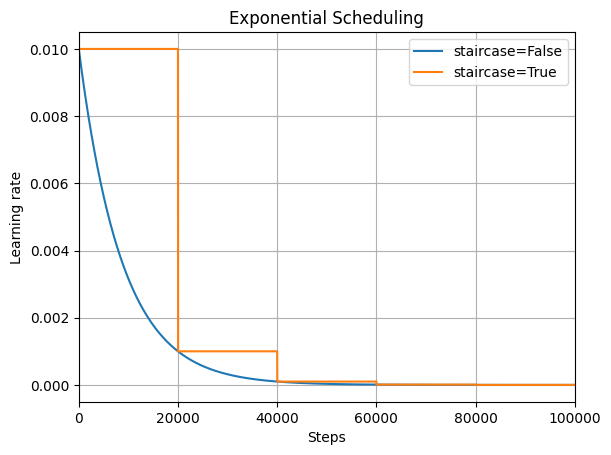

In [35]:
initial_learning_rate = 0.01
decay_rate = 0.1
decay_steps = 20_000

steps = np.arange(100_000)
lrs = initial_learning_rate * decay_rate**(steps / decay_steps)
lrs2 = initial_learning_rate * decay_rate**np.floor(steps / decay_steps)

plt.plot(steps, lrs, label='staircase=False')
plt.plot(steps, lrs2, label='staircase=True')
plt.xlim(0, 100_000)
plt.title('Exponential Scheduling')
plt.xlabel('Steps')
plt.ylabel('Learning rate')
plt.legend()
plt.grid()
plt.show()

In [36]:
def exponential_decay_fn(epoch):
    return 0.01 * 0.1**(epoch / 20)

In [37]:
def exponential_decay(lr0, s):
    def exponential_decay_fn(epoch):
        return lr0 * 0.1**(epoch / s)
    return exponential_decay_fn

exponential_decay_fn = exponential_decay(lr0=0.01, s=20)
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(exponential_decay_fn)

In [38]:
model = build_model()
optimizer = tf.keras.optimizers.SGD(learning_rate=0.001)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

In [39]:
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid),
                    callbacks=[lr_scheduler])

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 632us/step - accuracy: 0.7653 - loss: 0.6791 - val_accuracy: 0.8248 - val_loss: 0.4891 - learning_rate: 0.0100
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 593us/step - accuracy: 0.8353 - loss: 0.4656 - val_accuracy: 0.8424 - val_loss: 0.4433 - learning_rate: 0.0089
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 593us/step - accuracy: 0.8514 - loss: 0.4213 - val_accuracy: 0.8494 - val_loss: 0.4246 - learning_rate: 0.0079
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 593us/step - accuracy: 0.8601 - loss: 0.3952 - val_accuracy: 0.8544 - val_loss: 0.4113 - learning_rate: 0.0071
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 592us/step - accuracy: 0.8668 - loss: 0.3768 - val_accuracy: 0.8582 - val_loss: 0.4008 - learning_rate: 0.0063
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 592us/step - accuracy: 0.8717 - loss: 0.3628 - val_accuracy: 0.8614 - val_loss: 0.3922 - learning_rate: 0.0056
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 589us/step - accura

In [40]:
history.history['learning_rate']

[0.009999999776482582,
 0.008912509307265282,
 0.007943281903862953,
 0.007079457864165306,
 0.0063095735386013985,
 0.005623413249850273,
 0.005011872388422489,
 0.004466835875064135,
 0.003981071524322033,
 0.003548133885487914,
 0.003162277629598975,
 0.0028183830436319113,
 0.002511886414140463,
 0.0022387211211025715,
 0.00199526222422719,
 0.0017782794311642647,
 0.0015848932089284062,
 0.0014125375309959054,
 0.001258925418369472,
 0.0011220184387639165]

In [41]:
def exponential_decay_fn(epoch, lr):
    return lr * 0.1**(1 / 20)

In [42]:
class ExponentialDecay(tf.keras.callbacks.Callback):
    def __init__(self, n_steps=40_000):
        super().__init__()
        self.n_steps = n_steps

    def on_batch_begin(self, batch, logs=None):
        lr = self.model.optimizer.learning_rate.numpy()
        new_learning_rate = lr * 0.1 ** (1 / self.n_steps)
        self.model.optimizer.learning_rate.assign(new_learning_rate)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        logs['learning_rate'] = self.model.optimizer.learning_rate.numpy()

#### 구간별 고정 스케줄링

In [43]:
lr_schedule = tf.keras.optimizers.schedules.PiecewiseConstantDecay(
    boundaries=[50_000, 80_000],
    values=[0.01, 0.005, 0.001]
)
optimizer = tf.keras.optimizers.SGD(learning_rate=lr_schedule)

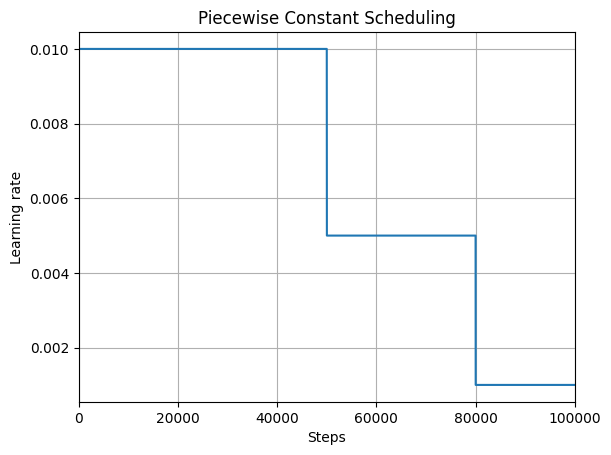

In [44]:
boundaries = [50_000, 80_000]
values = [0.01, 0.005, 0.001]

steps = np.arange(100_000)
lrs = np.full(len(steps), values[0])
for boundary, value in zip(boundaries, values[1:]):
    lrs[boundary:] = value

plt.plot(steps, lrs)
plt.xlim(0, 100_000)
plt.title('Piecewise Constant Scheduling')
plt.xlabel('Steps')
plt.ylabel('Learning rate')
plt.grid()
plt.show()

In [45]:
def piecewise_constant(boundaries, values):
    boundaries = np.array([0] + boundaries)
    values = np.array(values)
    def piecewise_constant_fn(epoch):
        return values[(boundaries > epoch).argmax() - 1]
    return piecewise_constant_fn

piecewise_constant_fn = piecewise_constant([5, 15], [0.01, 0.005, 0.001])
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(piecewise_constant_fn)

#### 성능 기반 스케줄링

In [46]:
model = build_model()
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

In [47]:
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5)
history = model.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=40,
                    callbacks=[lr_scheduler])

Epoch 1/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 626us/step - accuracy: 0.7670 - loss: 0.6804 - val_accuracy: 0.8220 - val_loss: 0.4983 - learning_rate: 0.0100
Epoch 2/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 585us/step - accuracy: 0.8366 - loss: 0.4652 - val_accuracy: 0.8296 - val_loss: 0.4593 - learning_rate: 0.0100
Epoch 3/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 585us/step - accuracy: 0.8511 - loss: 0.4192 - val_accuracy: 0.8418 - val_loss: 0.4304 - learning_rate: 0.0100
Epoch 4/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 580us/step - accuracy: 0.8600 - loss: 0.3917 - val_accuracy: 0.8480 - val_loss: 0.4126 - learning_rate: 0.0100
Epoch 5/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 583us/step - accuracy: 0.8661 - loss: 0.3714 - val_accuracy: 0.8540 - val_loss: 0.3930 - learning_rate: 0.0100
Epoch 6/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 585us/step - accuracy: 0.8712 - loss: 0.3559 - val_accuracy: 0.8560 - val_loss: 0.3881 - learning_rate: 0.0100
Epoch 7/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 579us/step - accura

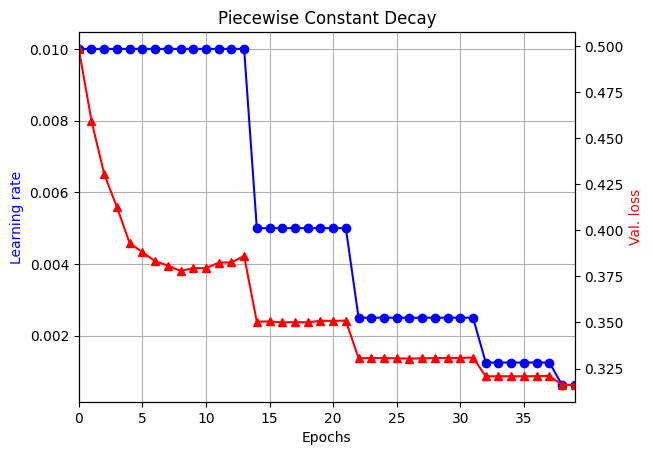

In [48]:
plt.plot(history.epoch, history.history['learning_rate'], 'bo-')
plt.xlabel('Epochs')
plt.ylabel('Learning rate', color='b')
plt.grid()
plt.xlim(0, max(history.epoch))
plt.title('Piecewise Constant Decay')
ax2 = plt.gca().twinx()
ax2.plot(history.epoch, history.history['val_loss'], 'r^-')
ax2.set_ylabel('Val. loss', color='r')
plt.show()

## 11.4 규제를 사용해 과대적합 피하기

### 11.4.1 $\ell_1$과 $\ell_2$ 규제

In [49]:
layer = tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal',
                              kernel_regularizer=tf.keras.regularizers.l2(0.01))

In [50]:
from functools import partial

RegularizedDense = partial(tf.keras.layers.Dense,
                           activation='relu',
                           kernel_initializer='he_normal',
                           kernel_regularizer=tf.keras.regularizers.l2(0.01))

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    RegularizedDense(100),
    RegularizedDense(100),
    RegularizedDense(10, activation='softmax')
])

### 11.4.2 드롭아웃

In [51]:
tf.random.set_seed(42)
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dropout(rate=0.2),
    tf.keras.layers.Dense(100, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dropout(rate=0.2),
    tf.keras.layers.Dense(10, activation='softmax')
])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.02)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

Epoch 1/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 628us/step - accuracy: 0.7339 - loss: 0.7566 - val_accuracy: 0.8266 - val_loss: 0.4796
Epoch 2/2
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 588us/step - accuracy: 0.8157 - loss: 0.5213 - val_accuracy: 0.8412 - val_loss: 0.4280


### 11.4.3 몬테 카를로 드롭아웃

In [52]:
y_probas = np.stack([model(X_test, training=True) for sample in range(100)])
y_proba = y_probas.mean(axis=0)

In [53]:
model.predict(X_test[:1]).round(3)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


array([[0.   , 0.   , 0.   , 0.001, 0.   , 0.176, 0.   , 0.217, 0.003,
        0.602]], dtype=float32)

In [54]:
y_proba[0].round(3)

array([0.001, 0.001, 0.001, 0.002, 0.001, 0.257, 0.001, 0.193, 0.011,
       0.531], dtype=float32)

In [55]:
y_std = y_probas.std(axis=0)
y_std[0].round(3)

array([0.002, 0.002, 0.004, 0.006, 0.005, 0.185, 0.003, 0.118, 0.025,
       0.188], dtype=float32)

In [56]:
model.evaluate(X_test, y_test)[1]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 402us/step - accuracy: 0.8347 - loss: 0.4606


0.8346999883651733

In [57]:
y_pred = y_proba.argmax(axis=1)
accuracy = (y_pred == y_test).sum() / len(y_test)
accuracy

np.float64(0.8316)

In [58]:
class MCDropout(tf.keras.layers.Dropout):
    def call(self, inputs, training=False):
        return super().call(inputs, training=True)

In [59]:
tf.random.set_seed(42)

dropout = tf.keras.layers.Dropout
mc_model = tf.keras.models.Sequential([
    MCDropout(layer.rate) if isinstance(layer, dropout) else layer for layer in model.layers
])
mc_model.set_weights(model.get_weights())

In [60]:
mc_model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mc_dropout (MCDropout)          │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mc_dropout_1 (MCDropout)        │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,610 (350.04 KB)

 Trainable params: 89,610 (350.04 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
tf.random.set_seed(42)
np.mean([mc_model.predict(X_test[:1]) for sample in range(100)], axis=0).round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.2 , 0.  , 0.24, 0.01, 0.54]],
      dtype=float32)

### 11.4.4 맥스-노름 규제

In [62]:
dense = tf.keras.layers.Dense(100, activation='relu',
                              kernel_initializer='he_normal',
                              kernel_constraint=tf.keras.constraints.MaxNorm(1.0))

## 연습문제

### ⑧

#### Step A

In [63]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten()
])
for _ in range(20):
    model.add(tf.keras.layers.Dense(100, activation='swish',
                                    kernel_initializer='he_normal'))

#### Step B - Basic MLP

In [64]:
cifar10 = tf.keras.datasets.cifar10.load_data()
(X_train_full, y_train_full), (X_test, y_test) = cifar10

X_train = X_train_full[5000:]
y_train = y_train_full[5000:]
X_valid = X_train_full[:5000]
y_valid = y_train_full[:5000]

In [65]:
model.add(tf.keras.layers.Dense(10, activation='softmax'))

In [66]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20,
                                                     restore_best_weights=True)
optimizer = tf.keras.optimizers.Nadam(learning_rate=5e-5)

model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, validation_data=(X_valid, y_valid),
                    callbacks=[early_stopping_cb])

Epoch 1/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.1570 - loss: 3.7077 - val_accuracy: 0.2080 - val_loss: 2.1688
Epoch 2/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.2300 - loss: 2.0714 - val_accuracy: 0.2464 - val_loss: 2.0077
Epoch 3/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.2719 - loss: 1.9638 - val_accuracy: 0.2926 - val_loss: 1.9376
Epoch 4/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3044 - loss: 1.8941 - val_accuracy: 0.3252 - val_loss: 1.8562
Epoch 5/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3304 - loss: 1.8378 - val_accuracy: 0.3348 - val_loss: 1.8311
Epoch 6/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3474 - loss: 1.7893 - val_accuracy: 0.3466 - val_loss: 1.7800
Epoch 7/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3674 - loss: 1.7460 - val_accuracy: 0.3718 - val_loss: 1.7581
Epoch 8/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3790 - loss: 1

In [67]:
model.evaluate(X_valid, y_valid)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 799us/step - accuracy: 0.4456 - loss: 1.5780


[1.578004240989685, 0.4456000030040741]

#### Step C - BatchNormalization MLP

In [68]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten()
])
for _ in range(20):
    model.add(tf.keras.layers.Dense(100, kernel_initializer='he_normal'))
    model.add(tf.keras.layers.BatchNormalization()),
    model.add(tf.keras.layers.Activation('swish'))
model.add(tf.keras.layers.Dense(10, activation='softmax'))

In [69]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20,
                                                     restore_best_weights=True)
optimizer = tf.keras.optimizers.Nadam(learning_rate=5e-4)

model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, validation_data=(X_valid, y_valid),
                    callbacks=[early_stopping_cb])

Epoch 1/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.2528 - loss: 2.0334 - val_accuracy: 0.3158 - val_loss: 1.8775
Epoch 2/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.3602 - loss: 1.7751 - val_accuracy: 0.3492 - val_loss: 1.7928
Epoch 3/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4014 - loss: 1.6648 - val_accuracy: 0.3768 - val_loss: 1.7414
Epoch 4/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4366 - loss: 1.5805 - val_accuracy: 0.4028 - val_loss: 1.7269
Epoch 5/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4631 - loss: 1.5071 - val_accuracy: 0.3770 - val_loss: 1.8615
Epoch 6/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4904 - loss: 1.4370 - val_accuracy: 0.4084 - val_loss: 1.7250
Epoch 7/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5155 - loss: 1.3725 - val_accuracy: 0.4058 - val_loss: 1.7760
Epoch 8/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5381 - loss: 

In [70]:
model.evaluate(X_valid, y_valid)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 954us/step - accuracy: 0.4084 - loss: 1.7250


[1.7250128984451294, 0.4083999991416931]

#### Step D - Self-Normalizing(SELU + Lecun)

In [71]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Normalization(),
])
for _ in range(20):
    model.add(tf.keras.layers.Dense(100, activation='selu',
                                    kernel_initializer='lecun_normal'))
model.add(tf.keras.layers.Dense(10, activation='softmax'))

In [72]:
flatten_X_train = tf.keras.layers.Flatten()(X_train)
model.layers[1].adapt(flatten_X_train)

In [73]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20,
                                                     restore_best_weights=True)
optimizer = tf.keras.optimizers.Nadam(learning_rate=7e-4)

model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, validation_data=(X_valid, y_valid),
                    callbacks=[early_stopping_cb])

Epoch 1/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.3219 - loss: 1.8949 - val_accuracy: 0.3632 - val_loss: 1.7808
Epoch 2/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4003 - loss: 1.6925 - val_accuracy: 0.4086 - val_loss: 1.6991
Epoch 3/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4359 - loss: 1.5995 - val_accuracy: 0.4438 - val_loss: 1.6372
Epoch 4/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4612 - loss: 1.5348 - val_accuracy: 0.4580 - val_loss: 1.5980
Epoch 5/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4799 - loss: 1.4843 - val_accuracy: 0.4672 - val_loss: 1.5659
Epoch 6/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5042 - loss: 1.4324 - val_accuracy: 0.4654 - val_loss: 1.5449
Epoch 7/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5170 - loss: 1.3929 - val_accuracy: 0.4846 - val_loss: 1.5435
Epoch 8/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5309 - loss: 1

In [74]:
model.evaluate(X_valid, y_valid)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 881us/step - accuracy: 0.4886 - loss: 1.5149


[1.5148597955703735, 0.4885999858379364]

#### Step E - Dropout & MCDropout

In [75]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Normalization(),
])
for _ in range(20):
    model.add(tf.keras.layers.Dense(100, activation='selu',
                                    kernel_initializer='lecun_normal'))
model.add(tf.keras.layers.AlphaDropout(rate=0.1))
model.add(tf.keras.layers.Dense(10, activation='softmax'))

flatten_X_train = tf.keras.layers.Flatten()(X_train)
model.layers[1].adapt(flatten_X_train)

In [76]:
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20,
                                                     restore_best_weights=True)
optimizer = tf.keras.optimizers.Nadam(learning_rate=5e-4)

model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer,
              metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=100, validation_data=(X_valid, y_valid),
                    callbacks=[early_stopping_cb])

Epoch 1/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.3206 - loss: 1.9029 - val_accuracy: 0.3796 - val_loss: 1.7360
Epoch 2/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4088 - loss: 1.6726 - val_accuracy: 0.4220 - val_loss: 1.6224
Epoch 3/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4446 - loss: 1.5779 - val_accuracy: 0.4422 - val_loss: 1.6400
Epoch 4/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4698 - loss: 1.5104 - val_accuracy: 0.4610 - val_loss: 1.5997
Epoch 5/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4930 - loss: 1.4538 - val_accuracy: 0.4634 - val_loss: 1.6030
Epoch 6/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5093 - loss: 1.4096 - val_accuracy: 0.4618 - val_loss: 1.6242
Epoch 7/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5254 - loss: 1.3656 - val_accuracy: 0.4810 - val_loss: 1.5650
Epoch 8/100
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5412 - loss: 1

In [77]:
model.evaluate(X_valid, y_valid)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step - accuracy: 0.4810 - loss: 1.5650


[1.564965009689331, 0.48100000619888306]

In [78]:
class MCAlphaDropout(tf.keras.layers.AlphaDropout):
    def call(self, inputs):
        return super().call(inputs, training=True)

In [79]:
mc_model = tf.keras.models.Sequential([
    (MCAlphaDropout(layer.rate)
     if isinstance(layer, tf.keras.layers.AlphaDropout) else layer)
    for layer in model.layers
])
mc_model.set_weights(model.get_weights())

In [80]:
def mc_dropout_predict_probas(mc_model, X, n_samples=10):
    y_probas = [mc_model.predict(X) for _ in range(n_samples)]
    return np.mean(y_probas, axis=0)

def mc_dropout_predict_classes(mc_model, X, n_samples=10):
    y_probas = mc_dropout_predict_probas(mc_model, X, n_samples)
    return y_probas.argmax(axis=1)

In [81]:
tf.random.set_seed(42)

y_pred = mc_dropout_predict_classes(mc_model, X_valid, 10)
accuracy = (y_pred == y_valid[:, 0]).mean()

accuracy

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 780us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 779us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 776us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 776us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 774us/step


np.float64(0.4804)